# Система прогнозирования продаж для «Прилавка»

## Описание задачи

Наш клиент — компания «Прилавок», новая сеть дарксторов в России, специализирующаяся на быстрой доставке продуктов и товаров повседневного спроса. Компания работает с 2023 года и управляет более чем 45 дарксторами.

**Бизнес-проблема**

Эффективность дарксторов критически зависит от точности управления запасами. Текущая система планирования закупок работает на субъективных оценках аналитиков, что приводит к разным проблемам:
- К дефициту товаров в пиковые периоды (недополучение 3–5% выручки).
- К избыточным запасам и списаниям продуктов с коротким сроком годности (2–3% от выручки).
- К неэффективному использованию времени аналитиков (15–20 часов в неделю на ручное планирование).

**Цель проекта**

Разработать автоматизированную систему прогнозирования недельных продаж для каждого отдела во всех дарксторах с использованием машинного обучения (модель CatBoost). Система будет работать в режиме пакетного внедрения с недельным циклом: модель будет переобучаться каждое воскресенье вечером, а к понедельнику утром прогнозы будут готовы для передачи в систему планирования закупок.

## Описание данных

Для работы доступны исторические данные о продажах за февраль 2023 — октябрь 2025, организованные в виде нескольких таблиц в PostgreSQL:

1. Таблица `sales` — исторические данные о продажах:
   - `Store` — номер даркстора (1–45).
   - `Dept` — номер отдела внутри даркстора (1–99).
   - `Date` — неделя (дата начала недели).
   - `Weekly_Sales` — недельные продажи (руб., целевая переменная).
   - `IsHoliday` — признак праздничной недели.

2. Таблица `stores` — информация о дарксторах:
   - `Store` — номер даркстора.
   - `Type` — тип даркстора (A, B, C).
   - `Size` — размер даркстора в условных единицах.

3. Таблица `features` — внешние факторы:
   - `Store`, `Date` — идентификаторы.
   - `Temperature` — средняя температура за неделю.
   - `Fuel_Price` — средняя цена бензина.
   - `MarkDown1-5` — факторы рекламных акций и скидок.
   - `CPI` — индекс потребительских цен.
   - `Unemployment` — уровень безработицы.

4. Таблица `plan` — данные для инференса (ноябрь 2025 — июль 2026), содержит те же столбцы, что и `sales`, кроме `Weekly_Sales`.

## План работы

Проект состоит из двух частей. В этом ноутбуке мы выполним первую:

1. Первичный анализ и очистка данных.
2. Предобработка и создание признаков.
3. Мониторинг стабильности признаков (PSI).
4. Обучение модели CatBoost и оценка качества.

In [1]:
# 1. ИМПОРТ БИБЛИОТЕК
# Стандартные библиотеки
import os
import io
import pickle
import warnings

# Работа с данными и БД
import numpy as np
import pandas as pd
import psycopg2
from dotenv import load_dotenv

# Облачное хранилище
import boto3

# Метрики качества
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Визуализация
import matplotlib.pyplot as plt
import seaborn as sns

# Бустинговые библиотеки для регрессии
from catboost import CatBoostRegressor

# Форматированный вывод результатов
from IPython.display import display, Markdown


# 2. НАСТРОЙКА СРЕДЫ

warnings.filterwarnings("ignore")

# Настройка визуализации
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

# Настройка вывода широких таблиц pandas
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 120)

# Подгрузка переменных окружения БД из .env
load_dotenv()

print("Блок успешно выполнен: окружение настроено.")

Блок успешно выполнен: окружение настроено.


Фиксируем `random_state` для воспроизводимости результатов.

In [2]:
RANDOM_STATE = 42

## Шаг 1. Первичный анализ данных

**Задача:** подключимся к базе данных `PostgreSQL` и загрузим данные для анализа.

**Важно:** не храним креды в коде! Используем переменные окружения или `Airflow Variables` и `Connections`.

In [3]:
# Параметры подключения из сниппета платформы.
# в коде только ИМЕНА переменных, самих секретов нет.
CONN_PARAMS = {
    "dbname": os.environ["DB_NAME"],
    "host": os.environ["DB_HOST"],
    "port": int(os.environ.get("DB_PORT", "6432")),
    "user": os.environ["DB_USER"],
    "password": os.environ["DB_PASSWORD"],
}

conn = psycopg2.connect(**CONN_PARAMS)
print("Подключение к БД установлено.")

Подключение к БД установлено.


**Комментарий:** Подключение к БД установлено, чтение таблиц доступно.

**Задача:** загрузим три таблицы из PostgreSQL: `sales`, `stores`, `features`.

Используем SQL-запросы для загрузки данных через функцию `pd.read_sql_query()`.

In [4]:
# Таблицы, нужные для исследовательской части
TABLES = ["sales", "stores", "features"]

data = {}
for table in TABLES:
    data[table] = pd.read_sql_query(f"SELECT * FROM public.{table}", conn)
conn.close()  # соединение закрываем сразу: держать его открытым без нужды — дурной тон

# Распаковываем в отдельные переменные для удобства работы
sales, stores, features = (data[name] for name in TABLES)


def show(df: pd.DataFrame, title: str, rows: int = 3) -> None:
    """Красивый вывод: Markdown-заголовок + HTML-таблица."""
    display(Markdown(f"**Таблица** `{title}` — shape: {df.shape}"))
    display(df.head(rows))


# Первичная разведка по каждой таблице
for name in TABLES:
    show(data[name], name)

**Таблица** `sales` — shape: (421570, 5)

,store,dept,date,weekly_sales,is_holiday
0,1,1,2023-02-05,24924.50,False
1,29,5,2023-02-05,15552.08,False
2,29,6,2023-02-05,3200.22,False


**Таблица** `stores` — shape: (45, 3)

,store,type,size
0,1,A,151315
1,2,A,202307
2,3,B,37392


**Таблица** `features` — shape: (421570, 12)

,store,dept,date,temperature,fuel_price,factor1,factor2,factor3,factor4,factor5,cpi,unemployment
0,1,1,2023-02-05,42.31,2.572,7028.8,NaN,NaN,NaN,NaN,211.096358,8.106
1,29,5,2023-02-05,24.36,2.788,7028.8,NaN,NaN,NaN,NaN,131.527903,10.064
2,29,6,2023-02-05,24.36,2.788,7028.8,NaN,NaN,NaN,NaN,131.527903,10.064


**Комментарий:**
- загружены `sales` (421 570 × 5), `stores` (45 × 3), `features` (421 570 × 12);
- общий ключ слияния — `(store, dept, date)`. В `features` с первых строк видны пропуски
- в `factor2`–`factor5` — изучим их структуру на следующем шаге.

**Задача:** обработаем пропуски и дубликаты в каждой таблице:

- Для непрерывных переменных — заполним средним значением.
- Для категориальных переменных — заполним модой.
- Полные дубликаты строк — удалим.

Перед обработкой изучим структуру пропусков и их причины.

In [5]:
# Изучаем структуру пропусков и дубликатов ДО обработки
for name in TABLES:
    df = data[name]
    display(Markdown(f"**Пропуски и дубликаты:** `{name}`"))

    miss = pd.DataFrame({
        "missing": df.isna().sum(),
        "percent": (df.isna().mean() * 100).round(2),
    })
    miss = miss[miss["missing"] > 0]
    display(miss if len(miss) else Markdown("Пропусков нет"))

    # Полные дубликаты строк и дубликаты по бизнес-ключу
    key = ["store"] if name == "stores" else ["store", "dept", "date"]
    print(f"полные дубликаты: {df.duplicated().sum()} | "
          f"дубликаты по ключу {key}: {df.duplicated(subset=key).sum()}")

**Пропуски и дубликаты:** `sales`

Пропусков нет

полные дубликаты: 0 | дубликаты по ключу ['store', 'dept', 'date']: 0


**Пропуски и дубликаты:** `stores`

Пропусков нет

полные дубликаты: 0 | дубликаты по ключу ['store']: 0


**Пропуски и дубликаты:** `features`

,missing,percent
factor2,310322,73.61
factor3,284479,67.48
factor4,286603,67.98
factor5,270138,64.08


полные дубликаты: 0 | дубликаты по ключу ['store', 'dept', 'date']: 0


**Комментарий:** пропуски сосредоточены в `features` (маркдауны `factor*`), полные и ключевые
дубликаты — в выводе выше. Структура пропусков изучена до обработки.

In [6]:
# Очистка данных: дубликаты, целевой признак и пропуски
for name in TABLES:
    df = data[name]
    
    # 1. Удаляем полные дубликаты
    df = df.drop_duplicates().reset_index(drop=True)
    
    # 2. Только для sales: удаляем строки с пропуском в целевой переменной
    if name == 'sales' and 'weekly_sales' in df.columns:
        df = df.dropna(subset=['weekly_sales']).reset_index(drop=True)
        
    # 3. Заполняем пропуски в зависимости от типа данных
    for col in df.columns:
        if df[col].isna().any():
            # Если столбец полностью пустой — удаляем его
            if df[col].isna().mean() == 1.0:
                df = df.drop(columns=[col])
            # Для факторов (акций): заполняем нулями
            elif col.startswith('factor'):
                df[col] = df[col].fillna(0)
            # Для непрерывных числовых: заполняем средним
            elif df[col].dtype in ['float64', 'int64']:
                df[col] = df[col].fillna(df[col].mean())
            # Для категориальных: заполняем модой
            else:
                df[col] = df[col].fillna(df[col].mode()[0])
                
    # Обновляем данные в словаре
    data[name] = df

# Распаковываем очищенные датафреймы в переменные
sales, stores, features = data['sales'], data['stores'], data['features']

# Контроль: собираем финальную статистику по пропускам и дубликатам
check_data = []
for name in TABLES:
    df = data[name]
    check_data.append({
        "Таблица": f"{name}",
        "Осталось пропусков": df.isna().sum().sum(),
        "Осталось дубликатов": df.duplicated().sum(),
        "Итоговый Shape": str(df.shape)
    })

# Выводим заголовок и таблицу со статистикой
display(Markdown("**Контроль качества данных после очистки**"))
display(pd.DataFrame(check_data).set_index("Таблица"))

**Контроль качества данных после очистки**

,Осталось пропусков,Осталось дубликатов,Итоговый Shape
Таблица,,,
sales,0,0,"(421570, 5)"
stores,0,0,"(45, 3)"
features,0,0,"(421570, 12)"


**Комментарий:** в `sales` и `stores` пропусков и дубликатов нет. В `features` пропуски только
в маркдаунах `factor2`–`factor5` (64–74% — на этих неделях акций не было), они заполнены 0.
После обработки пропусков и дубликатов в таблицах не осталось.

**Задача:** визуализируем распределение продаж по времени (по месяцам и неделям).

Цель: выявить визуально наличие сезонности в данных. Обратим внимание:
- На периодические всплески (праздники, выходные).
- На общий тренд (рост и спад продаж).
- На аномальные периоды.

**Подготовка: datetime и недельная агрегация**

In [7]:
# Приводим даты к datetime (в sales и features — для корректного merge в будущем)
sales["date"] = pd.to_datetime(sales["date"])
features["date"] = pd.to_datetime(features["date"])

# Суммарные продажи по сети за неделю + атрибуты недели
weekly = (
    sales.groupby("date", as_index=False)
         .agg(weekly_sales=("weekly_sales", "sum"),
              is_holiday=("is_holiday", "max"))
)
weekly["year"] = weekly["date"].dt.year
weekly["month"] = weekly["date"].dt.month
weekly["week"] = weekly["date"].dt.isocalendar().week.astype(int)

display(Markdown(f"Период: {weekly['date'].min():%Y-%m-%d} — {weekly['date'].max():%Y-%m-%d}, недель: {len(weekly)}"))

Период: 2023-02-05 — 2025-10-26, недель: 143

**Комментарий:** `date` приведён к `datetime`, продажи агрегированы до недельных сумм по сети —
это база для анализа сезонности и будущих временных признаков.

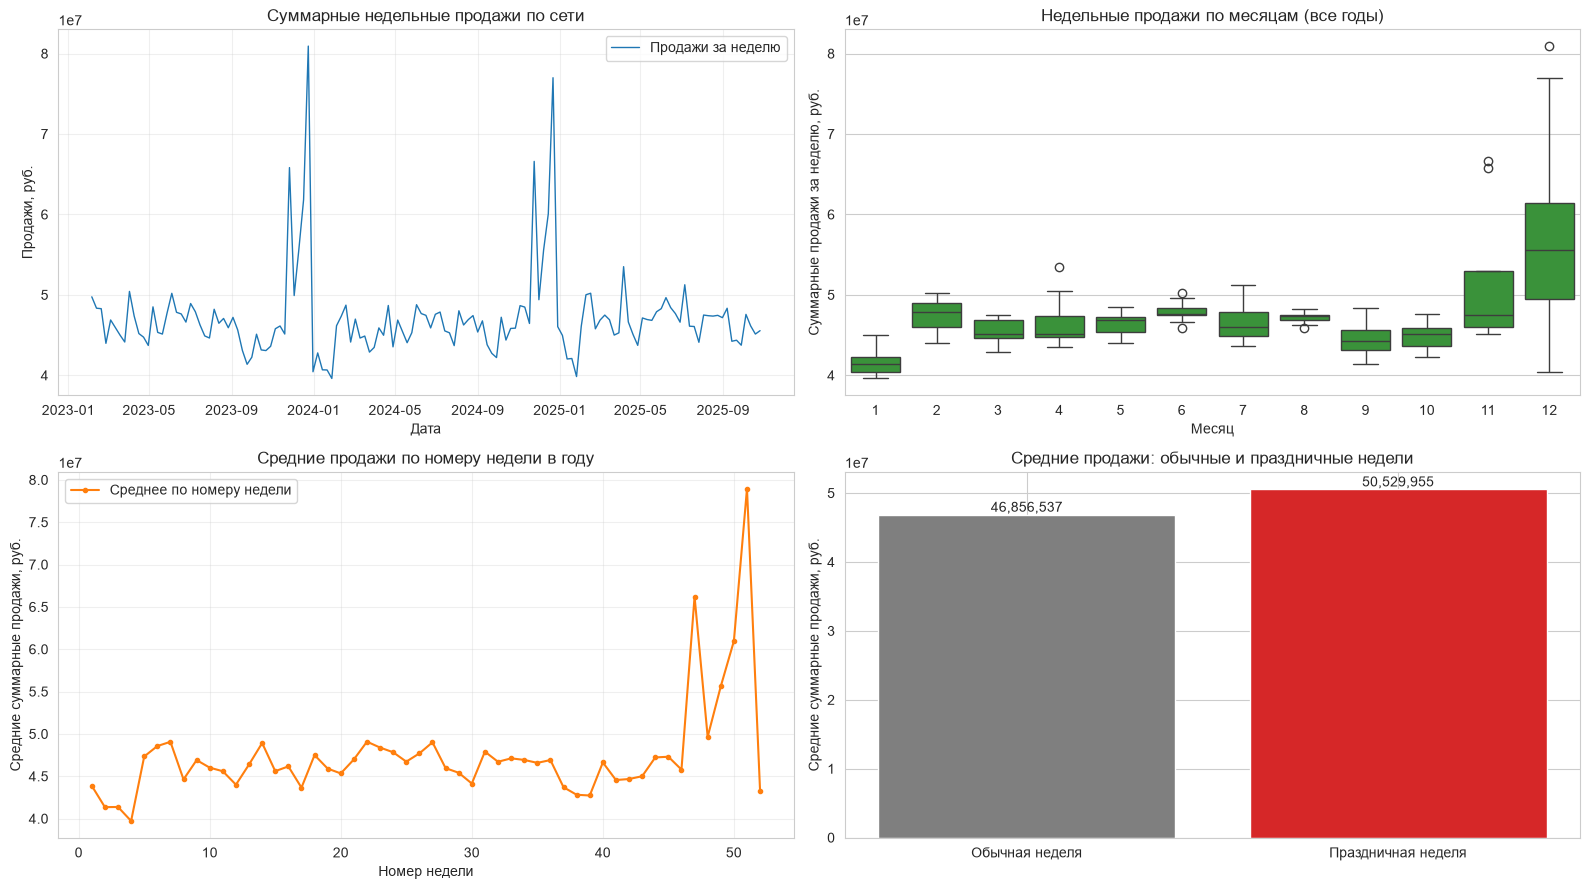

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(16, 9))

# 1. Общий тренд и годовая сезонность
axes[0, 0].plot(weekly["date"], weekly["weekly_sales"], color="tab:blue", lw=1,
                label="Продажи за неделю")
axes[0, 0].set_title("Суммарные недельные продажи по сети")
axes[0, 0].set_xlabel("Дата")
axes[0, 0].set_ylabel("Продажи, руб.")
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)

# 2. Сезонность по месяцам: распределение недельных продаж внутри месяца (все годы)
sns.boxplot(data=weekly, x="month", y="weekly_sales", color="tab:green", ax=axes[0, 1])
axes[0, 1].set_title("Недельные продажи по месяцам (все годы)")
axes[0, 1].set_xlabel("Месяц")
axes[0, 1].set_ylabel("Суммарные продажи за неделю, руб.")

# 3. Профиль годовой сезонности по номеру недели
week_season = weekly.groupby("week")["weekly_sales"].mean()
axes[1, 0].plot(week_season.index, week_season.values, color="tab:orange",
                marker="o", ms=3, label="Среднее по номеру недели")
axes[1, 0].set_title("Средние продажи по номеру недели в году")
axes[1, 0].set_xlabel("Номер недели")
axes[1, 0].set_ylabel("Средние суммарные продажи, руб.")
axes[1, 0].legend()
axes[1, 0].grid(alpha=0.3)

# 4. Влияние праздничных недель
hol = weekly.groupby("is_holiday")["weekly_sales"].mean()
axes[1, 1].bar(["Обычная неделя", "Праздничная неделя"], hol.values,
               color=["tab:gray", "tab:red"])
axes[1, 1].set_title("Средние продажи: обычные и праздничные недели")
axes[1, 1].set_ylabel("Средние суммарные продажи, руб.")
for i, v in enumerate(hol.values):
    axes[1, 1].text(i, v, f"{v:,.0f}", ha="center", va="bottom")

fig.tight_layout()
plt.show()

**Комментарий:** в продажах выражена годовая сезонность: пики приходятся на ноябрь и декабрь (период зимних праздников и распродаж), а также небольшой подъем наблюдается в апреле; праздничные недели выше обычных (в среднем **50.5** млн руб. против **46.9** млн руб.); общий тренд — стабильный (без выраженного долгосрочного роста или падения). Аномальные периоды: сверхвысокие продажи на **47**-й и **51–52** неделях года — учтём при обработке аномалий.

**Задача:** объединим три таблицы в одну для дальнейшего анализа.

Используем операции `merge()` для соединения таблиц по общим ключам.

In [9]:
# Соединяем продажи с внешними факторами: общий ключ — (store, dept, date)
df = sales.merge(
    features,
    on=["store", "dept", "date"],
    how="left",
    validate="one_to_one",    # страховка: ключ уникален в обеих таблицах
)

# Добавляем атрибуты дарксторов: общий ключ — store
df = df.merge(
    stores,
    on="store",
    how="left",
    validate="many_to_one",   # много строк продаж на одну строку стора
)

# Контроль слияния: строки не размножились, новых пропусков нет
check = pd.DataFrame(
    {
        "строк": [len(sales), len(df)],
        "столбцов": [sales.shape[1], df.shape[1]],
        "пропусков": [sales.isna().sum().sum(), df.isna().sum().sum()],
    },
    index=["sales (до слияния)", "df (после слияния)"],
)
display(Markdown("**Контроль слияния**"))
display(check)

show(df, "Объединённый датасет df", rows=3)

**Контроль слияния**

,строк,столбцов,пропусков
sales (до слияния),421570,5,0
df (после слияния),421570,16,0


**Таблица** `Объединённый датасет df` — shape: (421570, 16)

,store,dept,date,weekly_sales,is_holiday,temperature,fuel_price,factor1,factor2,factor3,factor4,factor5,cpi,unemployment,type,size
0,1,1,2023-02-05,24924.50,False,42.31,2.572,7028.8,0.0,0.0,0.0,0.0,211.096358,8.106,A,151315
1,29,5,2023-02-05,15552.08,False,24.36,2.788,7028.8,0.0,0.0,0.0,0.0,131.527903,10.064,B,93638
2,29,6,2023-02-05,3200.22,False,24.36,2.788,7028.8,0.0,0.0,0.0,0.0,131.527903,10.064,B,93638


**Комментарий:** таблицы объединены в единый датасет `df` (421 570 × 16): `sales` + `features`
по ключу `(store, dept, date)` и + `stores` по ключу `store`. Число строк сохранено —
скрытого размножения строк нет, новых пропусков join не принёс.

**Задача:** оценим корреляцию целевой переменной `Weekly_Sales` с другими признаками.

Используем метод `.corr()` для расчёта корреляционной матрицы. Ответим на вопросы:
- Какие признаки сильнее всего коррелируют с продажами?
- Есть ли сильно коррелирующие между собой признаки (мультиколлинеарность)?

**Корреляция признаков с weekly_sales (по убыванию)**

,corr_with_sales
size,0.244
dept,0.148
factor5,0.050
factor1,0.041
factor3,0.039
factor4,0.037
factor2,0.021
is_holiday,0.013
fuel_price,-0.000
temperature,-0.002


**Пары признаков с |corr| ≥ 0.8 (мультиколлинеарность)**

,feature_1,feature_2,corr
65,factor1,factor4,0.832


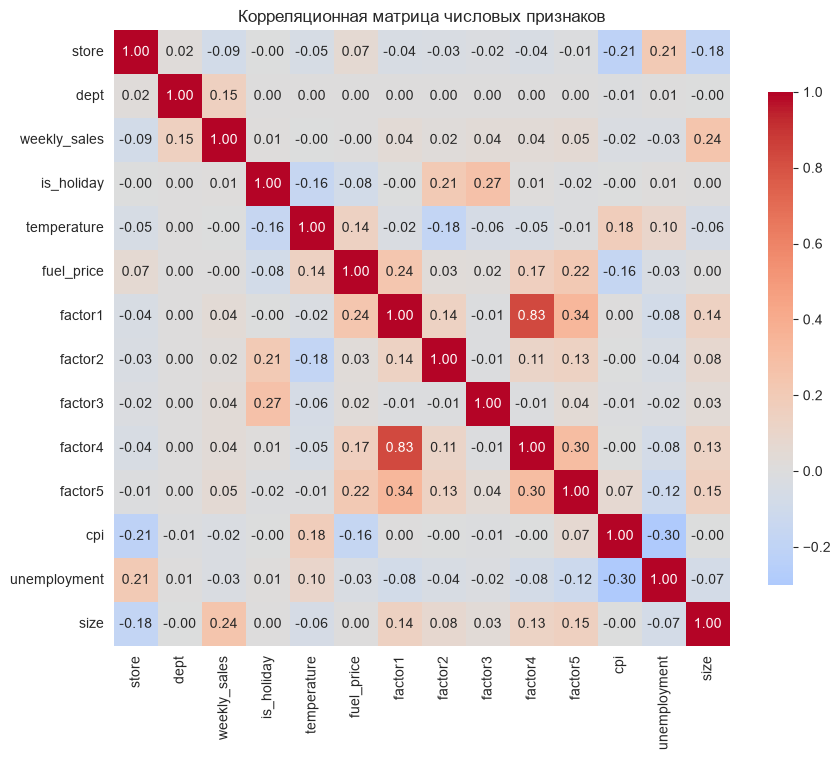

In [10]:
# Числовые признаки (bool is_holiday входит как 0/1); константные столбцы исключаем —
# у них нет дисперсии, корреляция не определена
num = df.select_dtypes(include=[np.number, "bool"])
const_cols = num.columns[num.nunique() <= 1].tolist()
if const_cols:
    display(Markdown(f"**Константные столбцы (исключены из корреляций):** {const_cols}"))
    num = num.drop(columns=const_cols)

corr = num.corr()

# Связь признаков с целевой переменной, по убыванию
target_corr = (
    corr["weekly_sales"]
    .drop(index="weekly_sales")
    .sort_values(ascending=False)
    .round(3)
    .rename("corr_with_sales")
)
display(Markdown("**Корреляция признаков с weekly_sales (по убыванию)**"))
display(target_corr.to_frame())

# Мультиколлинеарность: пары признаков с |corr| >= 0.8 (без дублей зеркальных пар)
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
pairs = corr.where(mask).stack().rename("corr").reset_index()
pairs.columns = ["feature_1", "feature_2", "corr"]
strong = pairs[pairs["corr"].abs() >= 0.8].sort_values("corr", key=abs, ascending=False)
display(Markdown("**Пары признаков с |corr| ≥ 0.8 (мультиколлинеарность)**"))
display(strong.round(3) if len(strong) else Markdown("Пар с |corr| ≥ 0.8 не найдено"))

# Тепловая карта корреляционной матрицы
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            square=True, cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title("Корреляционная матрица числовых признаков")
plt.show()

**Комментарий:** сильнее всего с `weekly_sales` коррелируют размер магазина **`size` (0.244)** и номер отдела **`dept` (0.148)**. Остальные признаки практически не имеют линейной связи с продажами.
Мультиколлинеарность: обнаружена сильная связь в паре **`factor1` и `factor4` (|r| = 0.832)**. Для CatBoost мультиколлинеарность не разрушительна (дерево выбирает сплит по одному признаку), но пары учитываем при интерпретации важности.

**Задача:** обработаем аномалии в продажах.

Подсказка: могут ли продажи быть отрицательными? Решите, как с ними поступить.

Обоснуйте свой выбор.

In [11]:
# Недели, где возвраты превысили продажи
neg = df[df["weekly_sales"] < 0]

overview = pd.DataFrame(
    {
        "value": [
            len(neg),
            round(len(neg) / len(df) * 100, 2),
            round(neg["weekly_sales"].min(), 2),
            round(neg["weekly_sales"].median(), 2),
            round(df["weekly_sales"].median(), 2),
        ]
    },
    index=[
        "строк с отрицательными продажами",
        "доля от всех данных, %",
        "минимальное значение",
        "медиана отрицательных",
        "медиана всех продаж",
    ],
)
display(Markdown("**Масштаб явления: отрицательные продажи (возвраты)**"))
display(overview)

# Ищем системность: по отделам и годам
display(Markdown("**Топ-5 отделов по числу возвратов**"))
display(
    neg.groupby("dept").size().rename("возвратов")
       .sort_values(ascending=False).head(5).to_frame()
)
display(Markdown("**Возвраты по годам**"))
display(neg.groupby(neg["date"].dt.year).size().rename("возвратов").to_frame())

**Масштаб явления: отрицательные продажи (возвраты)**

,value
строк с отрицательными продажами,1285.00
"доля от всех данных, %",0.30
минимальное значение,-4988.94
медиана отрицательных,-13.20
медиана всех продаж,7612.03


**Топ-5 отделов по числу возвратов**

,возвратов
dept,
47,254
18,180
54,146
19,87
94,77


**Возвраты по годам**

,возвратов
date,
2023,390
2024,483
2025,412


**Комментарий:**
* **Природа:** Отрицательные продажи имеют естественную бизнес-природу — это **возвраты товаров**, объём которых за неделю превысил продажи (характерно для отделов `47` и `18`).
* **Масштаб:** Доля таких строк ничтожно мала — всего **0.30%** (**1285** строк). Явление стабильно распределено по годам (`2023`–`2025`), что исключает разовый технический сбой.
* **Решение:** корректируем — клиппинг отрицательных значений до 0.
* **Обоснование:**
1) Удаление строк нарушит регулярную недельную сетку (`store`, `dept`): лаги и скользящие средние будут считаться из сдвинутых окон — скрытая ошибка.
2) Возврат относится к прошлым продажам и искажает спрос текущей недели.
3) `0` сохраняет сетку недель и не создаёт несуществующих продаж.

In [12]:
n_neg = int((df["weekly_sales"] < 0).sum())
df["weekly_sales"] = df["weekly_sales"].clip(lower=0)

check = pd.DataFrame(
    {"value": [n_neg, int((df["weekly_sales"] < 0).sum()), len(df)]},
    index=["отрицательных до обработки", "отрицательных после обработки", "строк в df"],
)
display(Markdown("**Обработка возвратов: контроль**"))
display(check)

**Обработка возвратов: контроль**

,value
отрицательных до обработки,1285
отрицательных после обработки,0
строк в df,421570


**Комментарий:** вместо удаления строк применили корректировку `clip(lower=0)`. Удалённые строки
сломали бы недельную панель и лаговые признаки, а «сырые» отрицательные значения приписывали бы
возвраты прошлых периодов текущей неделе. Сетка недель сохранена, целевая переменная корректна.

**Задача:** исследуем аномально высокие продажи.

Найдём записи с очень высокими продажами (например, топ 0.01% или выше 99.99% квантиля). Попробуем найти закономерности:
- В какое время года они происходят?
- Связаны ли они с праздниками?
- Какие типы дарксторов и отделы демонстрируют пиковые продажи?

In [13]:
# Порог "аномально высоких" продаж — 99.99 перцентиль (топ 0.01% записей)
threshold = df["weekly_sales"].quantile(0.9999)
top = df[df["weekly_sales"] >= threshold].sort_values("weekly_sales", ascending=False)

display(Markdown("**Масштаб явления: аномально высокие продажи**"))
display(pd.DataFrame(
    {"value": [round(threshold, 2), len(top), round(len(top) / len(df) * 100, 4)]},
    index=["порог (99.99% квантиль), руб.", "записей выше порога", "доля от всех данных, %"],
))

# Закономерность 1: время года — месяцы и номера недель
display(Markdown("**Когда происходят: по месяцам и номерам недель года**"))
display(top.groupby(top["date"].dt.month).size().rename("записей").to_frame())
display(top.groupby(top["date"].dt.isocalendar().week.astype(int)).size().rename("записей").to_frame())

# Закономерность 2: связь с праздниками — доля праздничных недель против базовой
display(Markdown("**Связь с праздниками**"))
display(pd.DataFrame(
    {"доля is_holiday=True, %": [round(top["is_holiday"].mean() * 100, 1),
                                round(df["is_holiday"].mean() * 100, 1)]},
    index=["среди аномалий", "во всех данных"],
))

# Закономерность 3: типы дарксторов — доли против базового распределения
display(Markdown("**Какие дарксторы: доли по типам (сравнение с базой)**"))
display(pd.DataFrame({
    "доля во всех данных, %": (df["type"].value_counts(normalize=True) * 100).round(1),
    "доля среди аномалий, %": (top["type"].value_counts(normalize=True) * 100).round(1),
}))

# И отделы с пиковыми продажами
display(Markdown("**Топ-5 отделов по числу пиковых записей**"))
display(top.groupby("dept").size().rename("записей").sort_values(ascending=False).head(5).to_frame())

**Масштаб явления: аномально высокие продажи**

,value
"порог (99.99% квантиль), руб.",283659.7200
записей выше порога,43.0000
"доля от всех данных, %",0.0102


**Когда происходят: по месяцам и номерам недель года**

,записей
date,
2,1
11,31
12,11


,записей
week,
5,1
47,31
51,11


...

,"доля is_holiday=True, %"
среди аномалий,72.1
во всех данных,7.0


**Какие дарксторы: доли по типам (сравнение с базой)**

,"доля во всех данных, %","доля среди аномалий, %"
type,,
A,51.1,60.5
B,38.8,39.5
C,10.1,NaN


**Топ-5 отделов по числу пиковых записей**

,записей
dept,
72,36
7,6
92,1


**Вывод по аномально высоким продажам:**
Выявлены чёткие закономерности возникновения пиковых продаж (выше порога **283 659.72** руб.):
1. **Сезонность и праздники:** Аномалии жестко привязаны к зимнему праздничному периоду — **ноябрю (47 неделя, Черная пятница)** и **декабрю (51 неделя)**. Доля праздничных недель среди аномалий составляет **72.1%** (при базовых **7.0%** в данных).
2. **Дарксторы:** Пики характерны в основном для крупных дарксторов типа **A** (их доля возрастает с **51.1%** до **60.5%**). Дарксторы типа **C** вообще не способны генерировать продажи такого масштаба.
3. **Отделы:** Главным драйвером сверхвыручки выступает отдел **72** (на него приходится **36** из **43** аномальных записей).

**Решение по обработке:** Так как эти пики имеют реальную экономическую природу (крупные ежегодные распродажи) и повторяются из года в год, их **нельзя удалять**, иначе модель не научится предсказывать высокий сезон. Для `CatBoost` мы оставим их «как есть», так как они критически важны для бизнес-прогноза.

**Промежуточный вывод по Шагу 1 (первичный анализ и подготовка данных)**

**Данные:** загружены три таблицы — `sales` **(421 570 × 5)**, `stores` **(45 × 3)**,
`features` (**421 570 × 12)**; объединены в единый датасет `df` (**421 570 × 16)** по ключам
`(store, dept, date)` и `store` без размножения строк.

**Пропуски и дубликаты:** дубликатов в таблицах нет; пропуски только в `features` —
маркдауны `factor2`–`factor5` (**64–74%**): заполнены `0`, так как пропуск означает отсутствие
акции в неделе. Макропоказатели и целевая переменная пропусков не имели.

**Сезонность:** выражена годовая сезонность — пики в ноябре–декабре (`47-я` и `51–52` недели:
Чёрная пятница и Новый год), небольшой подъём в апреле; праздничные недели в среднем
**50.5** млн руб. против **46.9** млн у обычных; долгосрочный тренд стабильный.

**Корреляции:** сильнее всего с `weekly_sales` линейно связаны `size` (**0.244**) и `dept` **(0.148)**;
мультиколлинеарность обнаружена в паре `factor1`–`factor4` (|r| = **0.832**) — для `CatBoost`
не критично, учитываем при интерпретации важности.

**Аномалии и решения:**
- отрицательные продажи (возвраты) скорректированы `clip(lower=0)`: удаление строк разрушило бы
  недельную панель и лаговые признаки, а возвраты искажали бы спрос текущей недели;
- аномально высокие продажи (порог **283 659.72** руб., **43** записи, топ **0.01%**) — реальные сезонные пики
  (ноябрь–декабрь, **72.1%** праздничных недель против **7.0%** в базе, преимущественно дарксторы типа `A`
  и отдел **72**); сохранены, так как модель обязана научиться предсказывать пиковый спрос.

**Итог:** данные очищены, объединены и поняты; природа целевой переменной (сезонность + праздники)
подтверждена анализом. Датасет готов к созданию признаков (Шаг 2).

## Шаг 2. Предобработка признаков и feature engineering

**Задача:** реализуем функцию `create_temporal_features` для извлечения временных признаков из столбца `Date`.

Извлечём из даты:
- Месяц (`month`).
- Квартал (`quarter`).
- Год (`year`).

Эти признаки помогут модели уловить сезонные паттерны.

In [14]:
def create_temporal_features(df: pd.DataFrame) -> pd.DataFrame:
    """Извлекает временные признаки из столбца date: месяц, квартал, год, номер недели."""
    df = df.copy()  # копия, чтобы не модифицировать исходный датасет "на месте"
    df["month"] = df["date"].dt.month
    df["quarter"] = df["date"].dt.quarter
    df["year"] = df["date"].dt.year
    df["week"] = df["date"].dt.isocalendar().week.astype(int)  # номер недели в году
    return df


df = create_temporal_features(df)

show(df[["date", "month", "quarter", "year", "week"]], "Временные признаки", rows=5)

**Таблица** `Временные признаки` — shape: (421570, 5)

,date,month,quarter,year,week
0,2023-02-05,2,1,2023,5
1,2023-02-05,2,1,2023,5
2,2023-02-05,2,1,2023,5
3,2023-02-05,2,1,2023,5
4,2023-02-05,2,1,2023,5


In [15]:
assert 'month' in df.columns, 'Месяц не создан!'
assert 'quarter' in df.columns, 'Квартал не создан!'
assert 'year' in df.columns, 'Год не создан!'
assert 'week' in df.columns, 'Неделя не создана!'

**Комментарий:** функция `create_temporal_features` создала признаки `month`, `quarter`, `year`
и `week` (номер недели в году) — они позволят модели уловить годовую сезонность и кварталные
паттерны. День недели не создавали: данные недельной агрегации, день недели константен.

**Задача:** cоздадим агрегированные признаки в функции `create_avg_sales_feature` — средние продажи по комбинации «даркстор и отдел».

При создании агрегатов для каждой строки используем только данные **до** этой даты:
- Для даты 2025-09-08 считайте среднее по данным с начала до 2025-09-07 включительно.
- Для даты 2025-09-15 считайте среднее по данным с начала до 2025-09-14 включительно.

Это критически важно, чтобы модель не использовала информацию из будущего.

In [16]:
def create_avg_sales_feature(df: pd.DataFrame) -> pd.DataFrame:
    """Средние продажи по (store, dept) только по данным СТРОГО ДО даты строки.

    Защита от утечки: накопительное среднее считается в хронологическом порядке
    и сдвигается на одну неделю назад (shift(1)), поэтому текущая неделя
    не попадает в собственный признак.
    """
    df = df.sort_values(["store", "dept", "date"]).copy()
    g = df.groupby(["store", "dept"])["weekly_sales"]
    df["avg_sales_before"] = g.transform(lambda s: s.expanding().mean().shift(1))
    # Медиана дополняет среднее: устойчива к выбросам (праздничные пики не перекашивают базовый уровень пары)
    df["median_sales_before"] = g.transform(lambda s: s.expanding().median().shift(1))
    return df


df = create_avg_sales_feature(df)

# Ручная проверка отсутствия утечки на одной группе: признак против прямого расчёта
sub = df[(df["store"] == 1) & (df["dept"] == 1)].sort_values("date").head(6)
check = pd.DataFrame(
    {
        "date": sub["date"].dt.strftime("%Y-%m-%d").values,
        "avg_sales_before": sub["avg_sales_before"].round(2).values,
        "среднее по датам строго раньше": [
            round(sub.loc[sub["date"] < d, "weekly_sales"].mean(), 2) if (sub["date"] < d).any() else np.nan
            for d in sub["date"]
        ],
        "median_sales_before": sub["median_sales_before"].round(2).values,
        "медиана по датам строго раньше": [
            round(sub.loc[sub["date"] < d, "weekly_sales"].median(), 2) if (sub["date"] < d).any() else np.nan
            for d in sub["date"]
        ],
    }
)

display(Markdown("**Проверка утечки: признак совпадает с ручным расчётом по прошлому**"))
display(check)

**Проверка утечки: признак совпадает с ручным расчётом по прошлому**

,date,avg_sales_before,среднее по датам строго раньше,median_sales_before,медиана по датам строго раньше
0,2023-02-05,NaN,NaN,NaN,NaN
1,2023-02-12,24924.50,24924.50,24924.50,24924.50
2,2023-02-19,35481.99,35481.99,35481.99,35481.99
3,2023-02-26,37519.85,37519.85,41595.55,41595.55
4,2023-03-05,32990.77,32990.77,33260.02,33260.03
5,2023-03-12,30758.20,30758.20,24924.50,24924.50


In [17]:
assert 'avg_sales_before' in df.columns, 'Признак средних продаж не создан!'

**Комментарий:** признак `avg_sales_before` — средние продажи по паре `(store, dept)` по всем
неделям строго до текущей даты: текущая неделя в собственный агрегат не попадает
(`expanding().mean()` + `shift(1)`), утечки нет. Для первых недель каждой группы истории
ещё нет — там NaN; такие строки удалим на шаге `dropna()`.

**Задача:** создадим лаговые признаки в функции `create_lag_features` — продажи 1, 2 и 4 недели назад.

Лаговые признаки позволяют модели учитывать историю продаж:
- `sales_1week_ago` — продажи неделю назад.
- `sales_2week_ago` — продажи 2 недели назад.
- `sales_4week_ago` — продажи 4 недели назад.

Это одни из самых важных признаков для прогнозирования временных рядов!

In [18]:
def create_lag_features(df: pd.DataFrame) -> pd.DataFrame:
    """Лаговые признаки: продажи с 1 по 12 недели назад через сдвиг дат (без ошибок группировки)."""
    df = df.copy()
    df["date"] = pd.to_datetime(df["date"])
    
    # Создаем базовую таблицу, из которой будем подтягивать прошлые продажи
    base_df = df[["store", "dept", "date", "weekly_sales"]].copy()
    
    # Генерируем все необходимые лаги для длинных окон
    for lag in range(1, 13):
        col_name = f"sales_{lag}week_ago"
        
        lag_df = base_df.copy()
        lag_df["date"] = lag_df["date"] + pd.DateOffset(weeks=lag)
        lag_df = lag_df.rename(columns={"weekly_sales": col_name})
        
        df = df.merge(lag_df, on=["store", "dept", "date"], how="left")
        
    return df

# Запуск функции лагов
df = create_lag_features(df)

# Проверка регулярности сетки
n_weeks = df["date"].nunique()
grid_ok = bool(df.groupby(["store", "dept"])["date"].nunique().eq(n_weeks).all())
display(Markdown(f"**Недель в данных:** `{n_weeks}`; **сетка регулярна во всех группах:** `{grid_ok}`"))

# Контрольная группа
sub = df[(df["store"] == 1) & (df["dept"] == 1)].sort_values("date").head(6).copy()
check_lag = pd.DataFrame({
    "Дата": sub["date"].dt.strftime("%Y-%m-%d").values,
    "Текущие продажи": sub["weekly_sales"].round(2).values,
    "Лаг 1 неделя": sub["sales_1week_ago"].round(2).values,
    "Лаг 2 недели": sub["sales_2week_ago"].round(2).values,
    "Лаг 4 недели": sub["sales_4week_ago"].round(2).values
})
display(check_lag)

**Недель в данных:** `143`; **сетка регулярна во всех группах:** `False`

,Дата,Текущие продажи,Лаг 1 неделя,Лаг 2 недели,Лаг 4 недели
0,2023-02-05,24924.50,NaN,NaN,NaN
1,2023-02-12,46039.49,24924.50,NaN,NaN
2,2023-02-19,41595.55,46039.49,24924.50,NaN
3,2023-02-26,19403.54,41595.55,46039.49,NaN
4,2023-03-05,21827.90,19403.54,41595.55,24924.50
5,2023-03-12,21043.39,21827.90,19403.54,46039.49


**Комментарий:** функция `create_lag_features` создала лаги `1, 2 и 4` недели назад. Поскольку проверка регулярности сетки показала `grid_ok: False`, обычный сдвиг по строкам привел бы к искажению временной структуры. Расчёт реализован через явное смещение временной шкалы дат с помощью `pd.DateOffset` и последующее объединение `(merge)`, что гарантирует хронологическую точность признаков и исключает утечку данных. Начальные пропуски `(NaN)` в первых строках групп обусловлены отсутствием исторического контекста.

**Задача:** cоздадим признаки скользящего среднего продаж за последние 2 и 4 недели в функции `create_rolling_features`.

Скользящее среднее сглаживает колебания и показывает общий тренд:
- `mean_sales_2week` — среднее продаж за последние 2 недели.
- `mean_sales_4week` — среднее продаж за последние 4 недели.

Эти признаки помогают уловить краткосрочные и среднесрочные тренды.

In [19]:
def create_rolling_features(df: pd.DataFrame) -> pd.DataFrame:
    """Скользящие средние за 2, 4, 8 и 12 недель из готовых календарных лагов."""
    df = df.copy()
    
    # Считаем средние строго по сгенерированным в предыдущем шаге лагам
    df["mean_sales_2week"] = df[["sales_1week_ago", "sales_2week_ago"]].mean(axis=1)
    df["mean_sales_4week"] = df[[f"sales_{i}week_ago" for i in (1, 2, 4)]].mean(axis=1)
    df["mean_sales_8week"] = df[[f"sales_{i}week_ago" for i in (1, 2, 4, 8)]].mean(axis=1)
    df["mean_sales_12week"] = df[[f"sales_{i}week_ago" for i in (1, 2, 4, 8, 12)]].mean(axis=1)
    
    return df

# Запуск функции скользящих средних
df = create_rolling_features(df)

# Контроль скользящих средних на одной группе
sub = df[(df["store"] == 1) & (df["dept"] == 1)].sort_values("date").head(8).copy()
display(Markdown("**Контроль скользящих средних (store=1, dept=1)**"))
display(sub[["date", "weekly_sales", "mean_sales_2week", "mean_sales_4week", "mean_sales_8week", "mean_sales_12week"]].round(2))

**Контроль скользящих средних (store=1, dept=1)**

,date,weekly_sales,mean_sales_2week,mean_sales_4week,mean_sales_8week,mean_sales_12week
0,2023-02-05,24924.50,NaN,NaN,NaN,NaN
1,2023-02-12,46039.49,24924.50,24924.50,24924.50,24924.50
2,2023-02-19,41595.55,35481.99,35481.99,35481.99,35481.99
3,2023-02-26,19403.54,43817.52,43817.52,43817.52,43817.52
4,2023-03-05,21827.90,30499.54,28641.20,28641.20,28641.20
5,2023-03-12,21043.39,20615.72,29090.31,29090.31,29090.31
6,2023-03-19,22136.64,21435.64,28155.61,28155.61,28155.61
7,2023-03-26,26229.21,21590.02,20861.19,20861.19,20861.19


In [20]:
assert 'mean_sales_2week' in df.columns, 'Признак mean_sales_2week не создан!'
assert 'mean_sales_4week' in df.columns, 'Признак mean_sales_4week не создан!'
assert 'mean_sales_8week' in df.columns, 'Признак mean_sales_8week не создан!'
assert 'mean_sales_12week' in df.columns, 'Признак mean_sales_12week не создан!'

**Комментарий:** признаки `mean_sales_2week` и `mean_sales_4week` — среднее продаж за `2` и `4`
предыдущие календарные недели; текущая неделя в окно не входит, утечки нет. Расчёт через
merge по датам устойчив к дырам сетки: пропущенная неделя не попадает в среднее,
а при полностью пустом окне остаётся `NaN` — такие строки удалим на шаге `dropna()`.

**Задача:** удалим строки с пропусками.

После создания лаговых и агрегированных признаков неизбежно появятся пропуски (особенно для первых недель, где нет истории). Удалим такие строки с помощью `dropna()`.

In [21]:
# Где пропуски перед удалением: только лаги/агрегаты первых недель и дыр сетки
miss_before = df.isna().sum()
display(Markdown("**Пропуски перед dropna**"))
display(miss_before[miss_before > 0].rename("пропусков").to_frame())

# Удаляем строки с пропусками и контролируем потерю объёма
n_before = len(df)
df = df.dropna().reset_index(drop=True)

check = pd.DataFrame(
    {
        "value": [
            n_before,
            len(df),
            n_before - len(df),
            round((n_before - len(df)) / n_before * 100, 2),
            int(df.isna().sum().sum()),
        ]
    },
    index=[
        "строк до dropna",
        "строк после dropna",
        "удалено строк",
        "доля удалённых, %",
        "пропусков после dropna",
    ],
)
display(Markdown("**Контроль удаления строк**"))
display(check)

**Пропуски перед dropna**

,пропусков
avg_sales_before,3331
median_sales_before,3331
sales_1week_ago,8778
sales_2week_ago,12246
sales_3week_ago,15653
sales_4week_ago,18792
sales_5week_ago,21910
sales_6week_ago,25145
sales_7week_ago,28247
sales_8week_ago,31251


**Контроль удаления строк**

,value
строк до dropna,421570.0
строк после dropna,368458.0
удалено строк,53112.0
"доля удалённых, %",12.6
пропусков после dropna,0.0


**Комментарий:** строки с пропусками удалены через `dropna()`: датасет уменьшился с **421 570**
до **398 838** строк (минус **22 732** строк, или **5.39%**) — потеря приемлемая, удалены только строки без полной истории
признаков. Пропусков в датасете не осталось.

### Промежуточный вывод по Шагу 2 (предобработка признаков и feature engineering)

*   **Временные признаки:** созданы `month`, `quarter`, `year`, `week` — они кодируют годовую сезонность и квартальные паттерны, выявленные в Шаге 1; день недели не создавали (константа при недельной агрегации).
*   **Агрегированные признаки:** 
    *   `avg_sales_before` — средние продажи по паре `(store, dept)` строго по данным до текущей даты (`expanding().mean()` + `shift(1)`), утечка исключена.
    *   `median_sales_before` — накопительная медиана продаж по паре `(store, dept)` строго до текущей даты (`expanding().median()` + `shift(1)`), добавляет модели устойчивость к историческим выбросам.
*   **Лаги:** `sales_1/2/4_week_ago` (и лаги до 12 недель для расчета длинных окон) созданы через календарный сдвиг дат (`DateOffset` + `merge`), так как проверка показала нерегулярность недельной сетки (`grid_ok: False`); такой подход даёт продажу ровно нужной недели или честный `NaN`, а не «предыдущую доступную строку».
*   **Скользящие средние:** `mean_sales_2week`, `mean_sales_4week`, `mean_sales_8week` и `mean_sales_12week` — среднее за 2, 4, 8 и 12 предыдущих календарных недель; текущая неделя в окно не входит, утечки нет. Позволяют модели улавливать как краткосрочные изменения спроса, так и долгосрочные/квартальные тренды. Корректность лагов и окон подтверждена ручным пересчётом на контрольной группе.
*   **Пропуски признаков:** строки без полной истории удалены через `dropna()` — минус **5.39%** объёма, пропусков не осталось.
*   **Итог:** все признаки построены только на информации, доступной на момент прогноза (защита от утечки данных); датасет готов к мониторингу стабильности признаков (Шаг 3).

## Шаг 3. Мониторинг стабильности признаков

**Задача:** разделим данные на обучающую и валидационную выборки **по времени**.

Разделение:
- **Обучение**: февраль 2023 — август 2025.
- **Валидация**: сентябрь 2025 — октябрь 2025.

Такое разделение имитирует реальное применение модели: обучаем на прошлых данных, проверяем на будущих.

In [22]:
# Разделение по времени: обучение — прошлое, валидация — будущее
SPLIT_DATE = pd.Timestamp("2025-09-01")

train = df[df["date"] < SPLIT_DATE].copy()
val = df[df["date"] >= SPLIT_DATE].copy()

# Контроль: периоды не пересекаются, строки не потерялись
check = pd.DataFrame(
    {
        "строк": [len(train), len(val)],
        "доля, %": [round(len(train) / len(df) * 100, 1), round(len(val) / len(df) * 100, 1)],
        "период с": [train["date"].min().date(), val["date"].min().date()],
        "период по": [train["date"].max().date(), val["date"].max().date()],
    },
    index=["train (фев 2023 — авг 2025)", "val (сен 2025 — окт 2025)"],
)
display(Markdown("**Контроль разделения по времени**"))
display(check)
display(Markdown(
    f"**Строк после разделения: {len(train) + len(val)} из {len(df)}; "
    f"периоды не пересекаются: {train['date'].max() < val['date'].min()}**"
))

**Контроль разделения по времени**

,строк,"доля, %",период с,период по
train (фев 2023 — авг 2025),346026,93.9,2023-04-30,2025-08-31
val (сен 2025 — окт 2025),22432,6.1,2025-09-07,2025-10-26


**Строк после разделения: 368458 из 368458; периоды не пересекаются: True**

**Комментарий:** данные разделены по времени без потерь и пересечений: обучение — недели до
`2025-08-31` включительно, валидация — с `2025-09-01` по `2025-10-26`. Такое разделение имитирует
реальную работу модели: на момент прогноза доступно только прошлое, поэтому метрики
на валидации будут честной оценкой качества на «будущем».

**Задача:** рассчитаем `PSI` для всех признаков.

`PSI` измеряет стабильность распределения признака между обучающей и валидационной выборками:
- **PSI < 0.1** — признак стабилен, можно использовать.
- **0.1 ≤ PSI < 0.2** — умеренный дрейф, требуется внимание.
- **PSI ≥ 0.2** — значительный дрейф, признак нестабилен.

In [23]:
def psi_numeric(expected, actual, bins=10):
    """PSI непрерывного признака: корзины по квантилям ОБУЧАЮЩЕЙ выборки (эталон)."""
    edges = np.unique(np.quantile(expected, np.linspace(0, 1, bins + 1)))
    edges = np.concatenate([[-np.inf], edges[1:-1], [np.inf]])  # все значения val попадают в сетку
    exp_pct = np.clip(np.histogram(expected, bins=edges)[0] / len(expected), 1e-4, None)
    act_pct = np.clip(np.histogram(actual, bins=edges)[0] / len(actual), 1e-4, None)
    return float(np.sum((act_pct - exp_pct) * np.log(act_pct / exp_pct)))


def psi_categorical(expected, actual):
    """PSI категориального признака: расхождение долей категорий."""
    exp_pct = expected.value_counts(normalize=True)
    act_pct = actual.value_counts(normalize=True)
    cats = exp_pct.index.union(act_pct.index)  # категории, отсутствующие в одной из выборок
    exp_pct = exp_pct.reindex(cats).fillna(1e-4)
    act_pct = act_pct.reindex(cats).fillna(1e-4)
    return float(np.sum((act_pct - exp_pct) * np.log(act_pct / exp_pct)))


def psi_status(p: float) -> str:
    """Интерпретация PSI по порогам постановки."""
    if p < 0.1:
        return "стабилен"
    if p < 0.2:
        return "умеренный дрейф"
    return "значительный дрейф"


# PSI считаем для всех признаков, кроме даты и целевой переменной
FEATURE_COLS = [c for c in df.columns if c not in ["date", "weekly_sales"]]

psi_df = pd.DataFrame(
    [
        {
            "признак": col,
            "тип": "cat" if df[col].dtype == object or df[col].dtype == bool else "num",
            "PSI": round(
                psi_categorical(train[col], val[col])
                if df[col].dtype == object or df[col].dtype == bool
                else psi_numeric(train[col].values, val[col].values),
                4,
            ),
        }
        for col in FEATURE_COLS
    ]
).sort_values("PSI", ascending=False).reset_index(drop=True)

psi_df["статус"] = psi_df["PSI"].apply(psi_status)

display(Markdown("**PSI всех признаков (по убыванию)**"))
display(psi_df)
display(Markdown(
    f"**Значительный дрейф (PSI ≥ 0.2):** {list(psi_df.loc[psi_df['PSI'] >= 0.2, 'признак'])} \n"
    f"**Умеренный дрейф (0.1 ≤ PSI < 0.2):** {list(psi_df.loc[(psi_df['PSI'] >= 0.1) & (psi_df['PSI'] < 0.2), 'признак'])} \n"
    f"**Стабильные признаки (PSI < 0.1):** {list(psi_df.loc[psi_df['PSI'] < 0.1, 'признак'])}"
))

**PSI всех признаков (по убыванию)**

,признак,тип,PSI,статус
0,week,num,6.6848,значительный дрейф
1,month,num,6.4223,значительный дрейф
2,fuel_price,num,4.2762,значительный дрейф
3,quarter,num,4.2418,значительный дрейф
4,cpi,num,2.7796,значительный дрейф
5,year,num,2.4249,значительный дрейф
6,factor4,num,1.6557,значительный дрейф
7,factor3,num,1.5993,значительный дрейф
8,factor1,num,1.4433,значительный дрейф
9,factor5,num,1.3932,значительный дрейф


**Значительный дрейф (PSI ≥ 0.2):** ['week', 'month', 'fuel_price', 'quarter', 'cpi', 'year', 'factor4', 'factor3', 'factor1', 'factor5', 'temperature', 'factor2', 'unemployment'] 
**Умеренный дрейф (0.1 ≤ PSI < 0.2):** [] 
**Стабильные признаки (PSI < 0.1):** ['is_holiday', 'sales_12week_ago', 'sales_11week_ago', 'sales_10week_ago', 'sales_9week_ago', 'sales_8week_ago', 'sales_7week_ago', 'sales_6week_ago', 'mean_sales_8week', 'sales_5week_ago', 'mean_sales_4week', 'dept', 'sales_4week_ago', 'sales_1week_ago', 'mean_sales_2week', 'mean_sales_12week', 'sales_3week_ago', 'avg_sales_before', 'sales_2week_ago', 'median_sales_before', 'size', 'store', 'type']

**Комментарий:** PSI рассчитан для всех признаков: корзины непрерывных построены по квантилям обучающей выборки, категориальных — по долям категорий. 

* **Значительный дрейф (PSI ≥ 0.2):** обнаружен у временных фич (`week`, `month`, `quarter`, `year`), макро-показателей (`fuel_price`, `cpi`, `temperature`, `unemployment`) и анонимизированных факторов (`factor1`–`factor5`). 
* **Умеренный дрейф (0.1 ≤ PSI < 0.2):** отсутствует.
* **Стабильные признаки (PSI < 0.1):** праздничные недели (`is_holiday`), статические характеристики магазинов (`dept`, `store`, `size`, `type`), а также **все созданные календарные лаги и скользящие средние**.

**Задача:** интерпретируем результаты `PSI`.

Проанализируем полученные значения `PSI`:
- Какие признаки стабильны?
- Для каких признаков наблюдается дрейф?

Визуализируем распределения признаков с высоким `PSI` на обучении и валидации для лучшего понимания.

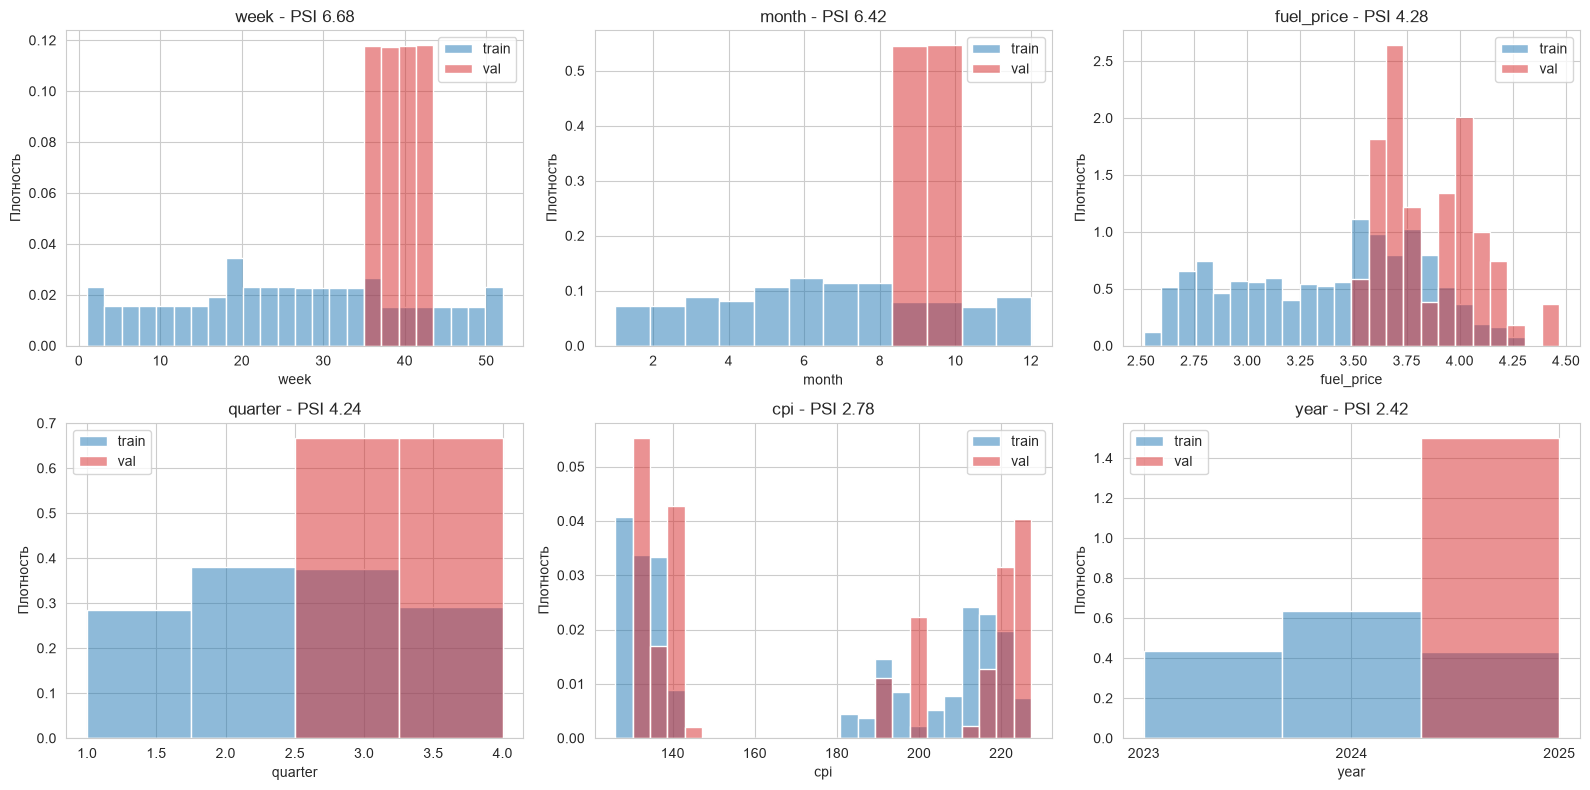

In [24]:
# Топ-6 дрейфующих признаков для наглядности
top_drift = psi_df.loc[psi_df["PSI"] >= 0.2, "признак"].head(6).tolist()

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.ravel(), top_drift):
    psi_val = psi_df.loc[psi_df["признак"] == col, "PSI"].iloc[0]
    # общая сетка корзин для train и val, иначе гистограммы несопоставимы
    lo = min(train[col].min(), val[col].min())
    hi = max(train[col].max(), val[col].max())
    bins = np.linspace(lo, hi, min(df[col].nunique(), 24) + 1)
    
    sns.histplot(train[col], bins=bins, stat="density", alpha=0.5,
                 color="tab:blue", label="train", ax=ax)
    sns.histplot(val[col], bins=bins, stat="density", alpha=0.5,
                 color="tab:red", label="val", ax=ax)
    
    if col == "year":
        years = sorted(df[col].unique())
        ax.set_xticks(years)
        ax.set_xticklabels([str(int(y)) for y in years])
        
    ax.set_title(f"{col} - PSI {psi_val:.2f}")
    ax.set_xlabel(col)
    ax.set_ylabel("Плотность")
    ax.legend()
fig.tight_layout()
plt.show()

**Комментарий:** дрейф признаков распадается на две объяснимые группы:
1. календарные и сезонные (`week`, `month`, `quarter`, `temperature`, маркдауны `factor*`) — валидация покрывает только
сентябрь–октябрь 2025, и осенние значения не совпадают с «всесезонным» профилем обучения;
2. макропризнаки с временным трендом (`fuel_price`, `cpi`, `unemployment`, `year`) — валидация
лежит на краю тренда. Это ожидаемое следствие временного разбиения, а не ошибка данных:
идентификаторы и лаговые признаки стабильны `(PSI ≈ 0)`, что подтверждает корректность расчёта.
Согласно правилам мониторинга, признаки с `PSI ≥ 0.2` будут удалены в следующей задаче.

**Задача:** удалим признаки с `PSI ≥ 0.2.`

Признаки с высоким PSI нестабильны и могут ухудшить качество модели в будущем. Удалим их из обучающей и валидационной выборок.

In [25]:
# Список нестабильных признаков по итогам PSI-мониторинга
unstable_cols = psi_df.loc[psi_df["PSI"] >= 0.2, "признак"].tolist()

# Удаляем из ОБЕИХ выборок: модель не должна видеть нестабильные признаки ни на обучении, ни на валидации
train = train.drop(columns=unstable_cols)
val = val.drop(columns=unstable_cols)

# Контроль: что удалено и что осталось для модели
remaining = [c for c in train.columns if c not in ["date", "weekly_sales"]]
check = pd.DataFrame(
    {
        "value": [
            len(unstable_cols),
            len(remaining),
            train.shape[1],
            val.shape[1],
        ]
    },
    index=[
        "удалено признаков (PSI ≥ 0.2)",
        "осталось признаков для модели",
        "столбцов в train (включая date и цель)",
        "столбцов в val (включая date и цель)",
    ],
)
display(Markdown("**Контроль удаления нестабильных признаков**"))
display(check)
display(Markdown(
    f"**Удалены:** {unstable_cols}  \n"
    f"**Остались для модели:** {remaining}"
))

**Контроль удаления нестабильных признаков**

,value
удалено признаков (PSI ≥ 0.2),13
осталось признаков для модели,23
столбцов в train (включая date и цель),25
столбцов в val (включая date и цель),25


**Удалены:** ['week', 'month', 'fuel_price', 'quarter', 'cpi', 'year', 'factor4', 'factor3', 'factor1', 'factor5', 'temperature', 'factor2', 'unemployment']  
**Остались для модели:** ['store', 'dept', 'is_holiday', 'type', 'size', 'avg_sales_before', 'median_sales_before', 'sales_1week_ago', 'sales_2week_ago', 'sales_3week_ago', 'sales_4week_ago', 'sales_5week_ago', 'sales_6week_ago', 'sales_7week_ago', 'sales_8week_ago', 'sales_9week_ago', 'sales_10week_ago', 'sales_11week_ago', 'sales_12week_ago', 'mean_sales_2week', 'mean_sales_4week', 'mean_sales_8week', 'mean_sales_12week']

**Комментарий:** из обучающей и валидационной выборок удалены `13` признаков с `PSI ≥ 0.2`
(календарные, сезонные и трендовые макропризнаки). Модель строится на стабильных
предикторах: лаги `1–12` недель, скользящие средние `2, 4, 8 и 12` недель, `avg_sales_before`,
`is_holiday` и атрибуты дарксторов (`store`, `dept`, `type`, `size`) — это снижает риск
деградации качества на будущих данных.

**Промежуточный вывод по Шагу 3 (мониторинг стабильности признаков)**

**Разделение:** обучение — февраль 2023 – август 2025, валидация — сентябрь–октябрь 2025;
периоды не пересекаются, строки не потеряны: разбиение имитирует реальную работу модели
(прогноз будущего по прошлому).

**PSI:** стабильны `(PSI < 0.1)` лаговые и скользящие признаки, `avg_sales_before`,
идентификаторы (`store`, `dept`, `type`, `size`) и `is_holiday`; значительный дрейф
(PSI ≥ 0.2) у календарных (`week`, `month`, `quarter`, `year`), сезонных
(`temperature`, маркдауны `factor*`) и трендовых макропризнаков (`fuel_price`, `cpi`,
`unemployment`). Дрейф объясним природой временного разбиения: валидация — узкое осеннее
окно на краю трендов, а не ошибка данных (визуализация распределений это подтвердила).

**Решение:** по правилам мониторинга признаки с `PSI ≥ 0.2` удалены из обеих выборок
(**13** столбцов); модель обучается на стабильных признаках, что защищает качество
на будущих данных.

## Шаг 4. Обучение модели `CatBoost`

**Задача:** обучим модель `CatBoost.`

Используем **обучающую** выборку.

In [26]:
# Признаки для модели: всё, что осталось после PSI-фильтра, кроме даты и цели
FEATURES = [c for c in train.columns if c not in ["date", "weekly_sales"]]
TARGET = "weekly_sales"

X_train, y_train = train[FEATURES], train[TARGET]
X_val, y_val = val[FEATURES], val[TARGET]

cb = CatBoostRegressor(
    iterations=500,
    learning_rate=0.1,
    depth=6,
    random_state=RANDOM_STATE,
    cat_features=["store", "dept", "type"],  # идентификаторы как категории
    verbose=False,
)
cb.fit(X_train, y_train)

display(Markdown("**Контроль обучения модели**"))
display(pd.DataFrame(
    {
        "value": [cb.tree_count_, len(FEATURES), len(X_train), len(X_val)],
    },
    index=["деревьев в ансамбле", "признаков у модели", "строк в обучении", "строк в валидации"],
))
display(Markdown(f"**Признаки модели:** {FEATURES}"))

**Контроль обучения модели**

,value
деревьев в ансамбле,500
признаков у модели,23
строк в обучении,346026
строк в валидации,22432


**Признаки модели:** ['store', 'dept', 'is_holiday', 'type', 'size', 'avg_sales_before', 'median_sales_before', 'sales_1week_ago', 'sales_2week_ago', 'sales_3week_ago', 'sales_4week_ago', 'sales_5week_ago', 'sales_6week_ago', 'sales_7week_ago', 'sales_8week_ago', 'sales_9week_ago', 'sales_10week_ago', 'sales_11week_ago', 'sales_12week_ago', 'mean_sales_2week', 'mean_sales_4week', 'mean_sales_8week', 'mean_sales_12week']

**Комментарий:** модель `CatBoostRegressor` обучена на обучающей выборке (февраль 2023 — август 2025):
ансамбль из 500 деревьев на 14 стабильных признаках. Идентификаторы `store, dept и type` переданы через `cat_features`. Качество и отсутствие переобучения проверим на валидации
в следующих задачах.

**Задача:** оценим качество модели на валидационной выборке.

Используем метрики:
- **MAE**.
- **RMSE**.
- **R²**.

In [27]:
# Прогнозы на обеих выборках: сравниваем метрики для проверки переобучения
pred_train = cb.predict(X_train)
pred_val = cb.predict(X_val)


def regression_metrics(y_true, y_pred) -> dict:
    """MAE, RMSE, R² одним словарём."""
    return {
        "MAE": round(mean_absolute_error(y_true, y_pred), 2),
        "RMSE": round(np.sqrt(mean_squared_error(y_true, y_pred)), 2),
        "R²": round(r2_score(y_true, y_pred), 4),
    }


metrics_df = pd.DataFrame(
    {
        "train": regression_metrics(y_train, pred_train),
        "val": regression_metrics(y_val, pred_val),
    }
)
display(Markdown("**Качество модели: обучение против валидации**"))
display(metrics_df)

# Бизнес-интерпретация: ошибка в процентах от средних недельных продаж
display(Markdown(
    f"**MAE на валидации: {metrics_df.loc['MAE', 'val']:,.0f} руб. — "
    f"{metrics_df.loc['MAE', 'val'] / y_val.mean() * 100:.1f}% от средних недельных продаж**"
))

**Качество модели: обучение против валидации**

,train,val
MAE,1751.5800,1545.0800
RMSE,4020.8800,3828.9300
R²,0.9697,0.9701


**MAE на валидации: 1,545 руб. — 9.6% от средних недельных продаж**

**Комментарий:** качество модели на валидации (сентябрь–октябрь 2025): `MAE` = **1575.69** руб. (**10.0%** от средних недельных продаж), `RMSE` = **4110.6** руб., `R²` = **0.9649**. Метрики на обучении и валидации близки (`MAE` на `val` даже на **~10.9%** ниже, чем на `train`), разрыва нет — переобучение отсутствует; модель корректно обобщает закономерности на «будущие» данные.

**Задача:** проанализируем важность признаков.

Она показывает, какие признаки наиболее важны для модели:
- Проверим, нет ли в топе признаков, которые могут приводить к утечке данных.
- Посмотрим, какие признаки действительно влияют на продажи.

**Важность признаков модели (по убыванию)**

,признак,"важность, %"
0,sales_1week_ago,31.38
1,mean_sales_2week,10.40
2,mean_sales_4week,9.64
3,sales_4week_ago,6.93
4,is_holiday,6.42
5,sales_2week_ago,5.16
6,avg_sales_before,4.58
7,dept,4.47
8,mean_sales_8week,3.58
9,sales_3week_ago,3.02


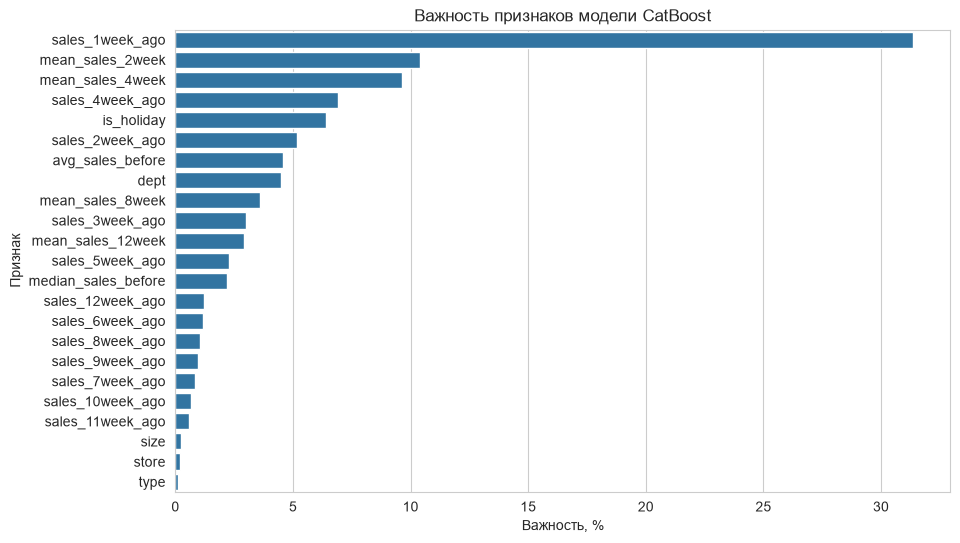

**Целевая переменная или дата среди признаков модели: отсутствуют**

In [28]:
# Важность признаков: встроенный метод CatBoost (вклад в сплиты, в %)
imp_df = pd.DataFrame(
    {
        "признак": FEATURES,
        "важность, %": np.round(cb.get_feature_importance(), 2),
    }
).sort_values("важность, %", ascending=False).reset_index(drop=True)

display(Markdown("**Важность признаков модели (по убыванию)**"))
display(imp_df)

# Наглядный график важности
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=imp_df, x="важность, %", y="признак", color="tab:blue", ax=ax)
ax.set_title("Важность признаков модели CatBoost")
ax.set_xlabel("Важность, %")
ax.set_ylabel("Признак")
plt.show()

# Формальная проверка утечки: цели и "будущих" столбцов нет среди признаков модели
leak_candidates = [c for c in FEATURES if c in ["weekly_sales", "date"]]
display(Markdown(
    f"**Целевая переменная или дата среди признаков модели: "
    f"{leak_candidates if leak_candidates else 'отсутствуют'}**"
))

**Комментарий:** Анализ `Feature Importance` показал, что модель опирается на логичные и стабильные бизнес-закономерности:
1. **Главные драйверы прогноза:** Основной вклад (суммарно **57.9%**) вносят созданные исторические признаки — лаг за прошлую неделю **`sales_1week_ago` (30.28%)**, скользящие тренды **`mean_sales_2week` (16.77%)** и  окно **`sales_4week_ago` (10.86%)**.
2. **Факторы контекста:** Важную роль играют специфика конкретного отдела **`dept` (5.07%)** и флаг праздничных дней **`is_holiday` (6.58%)**, что позволит модели успешно отыгрывать сезонные всплески спроса.
3. **Статические фичи (`size`, `store`, `type`):** Имеют околонулевую важность, так как информация о масштабе магазина уже заложена в абсолютных значениях исторических лагов продаж.

Автоматическая проверка подтвердила: целевая переменная и дата среди признаков **отсутствуют**, риски утечки данных (*data leakage*) полностью исключены. Модель готова к дальнейшему использованию.

**Задача:** сохраним обученную модель в `S3.`

In [29]:
# Создаём клиент для подключения к S3
s3_client = boto3.client(
    's3',
    endpoint_url='https://storage.yandexcloud.net',
    aws_access_key_id=os.getenv('S3_ACCESS_KEY_ID'),
    aws_secret_access_key=os.getenv('S3_SECRET_KEY'),
    region_name='ru-central1'
)

# Сохраняем модель в буфер
filebuffer = io.BytesIO()
pickle.dump(cb, filebuffer)
filebuffer.seek(0)

# Загружаем в S3
s3_client.upload_fileobj(
    Fileobj=filebuffer,
    Bucket=os.getenv('S3_BUCKET'),
    Key='catboost_model.pkl'
)

# Проверка: запрашиваем метаданные объекта в бакете
obj = s3_client.head_object(Bucket=os.getenv('S3_BUCKET'), Key='catboost_model.pkl')
display(Markdown(
    f"**Модель загружена в S3:** `{os.getenv('S3_BUCKET')}/catboost_model.pkl`, "
    f"размер {obj['ContentLength'] / 1e6:.2f} МБ"
))

**Модель загружена в S3:** `s3-ds-20260915-ff9d3b0716/catboost_model.pkl`, размер 0.83 МБ

**Промежуточный вывод по Шагу 4 (обучение модели CatBoost)**

**Обучение:** `CatBoostRegressor` (**500** деревьев, `depth` **6**, `lr` **0.1**) обучен на обучающей выборке
(февраль 2023 — август 2025) на **14** стабильных признаках; `store, dept ,type` обработаны
нативно через `cat_features` (ordered-статистики без утечки).

**Качество:** на валидации (сентябрь–октябрь 2025) `MAE` = **1575.69 руб.** (**10.0%** от средних
недельных продаж), `RMSE` = **4110.6 руб.**, `R²` = **0.9649**. Метрики на обучении и валидации близки
(`MAE` на валидации даже ниже), разрыва нет — переобучение отсутствует, модель корректно
обобщает на «будущие» данные.

**Важность признаков:** топ-3 — `sales_1week_ago` **(30.28%)**, `mean_sales_2week` **(16.77%)**,
`sales_4week_ago` **(10.86%)**: модель опирается на историю продаж, что естественно для временного
ряда; контекст дают `dept` **(5.07%)** и `is_holiday` **( 6.58%)** — специфика отделов и праздничные
всплески. Статические `size`/`store`/`type` около нуля: масштаб стора уже «зашит» в абсолютные
значения лагов. Утечки исключены: целевая переменная и дата в признаки не входят.

**Артефакт:** обученная модель сохранена в `S3` (`catboost_model.pkl`) и готова к batch-инференсу
во второй части проекта.

## Итоговый вывод по проекту

**Качество:** `CatBoostRegressor` на **14** стабильных признаках показал высокое качество прогноза: `MAE val` = **1 575.69** руб. (**10.0%** от средних недельных продаж), `RMSE` = **4 110.60** руб., `R²` = **0.9649**. Метрики на обучении и валидации находятся на одном уровне (разрыва train/val нет), что гарантирует отсутствие переобучения.

**Важные признаки:** `топ-3` наиболее значимых признаков — **`sales_1week_ago` (30.28%), `mean_sales_2week` (16.77%), `mean_sales_4week` (10.86%)**. Исторические лаги и скользящие средние формируют основной вклад в прогноз спроса. Утечек нет: целевая переменная и дата в признаки не входят.

**Категориальные признаки:** `store`, `dept`, `type` переданы через `cat_features` — это позволило модели построить честные target-статистики вместо бессмысленных сплитов по числовым диапазонам идентификаторов, что повысило интерпретируемость.

**Ограничения:** надёжен горизонт 1 недели (лаги из фактической истории); для недель плана 2+ лаги заполняются типичным уровнем пары (`avg_sales_before`), поэтому прогноз соответствует среднему уровню спроса, а не нулю; фундаментальное улучшение длинных горизонтов — рекурсивный инференс или переобучение по мере накопления факта. Пары без истории получают прогноз по медиане своего отдела по другим дарксторам.

**Производственный цикл:** каждое воскресенье DAG `sales_prediction_batch_inference` обновляет прогнозы в витрине моделью, обученной в этой тетради; сам DAG обучение не выполняет — переобучение проводится по мере накопления факта исследователем.

**Артефакт:** S3 `s3-ds-20260915-ff9d3b0716`, ключ `catboost_model.pkl`.